# Lab3: Stock price prediction
### Réalisé par: Abdelkader Arras
### EMSI 2025/2026


# T.A.F
1. Démarrer 
2. Analyser
3. Améliorer

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import SimpleRNN
from keras.layers import Dropout
from keras.layers import Dense

# Step 1: Dataset
 url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/NSE-TATAGLOBAL.csv'

In [12]:
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/NSE-TATAGLOBAL.csv'
dataset_train = pd.read_csv(url)
print(dataset_train.shape)
training_set = dataset_train.iloc[:, 1:2].values
#print(dataset_train.head())
#print(training_set)
# Data transformation
sc = MinMaxScaler(feature_range=(0,1))
training_set_scaled = sc.fit_transform(training_set)
#print(training_set_scaled)
X_train = []
y_train = []
for i in range(60, 2035):
    X_train.append(training_set_scaled[i-60:i, 0])
    y_train.append(training_set_scaled[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
#print(X_train)


(2035, 8)


# Step 2: Model

In [13]:
# Initialize the RNN model
model = Sequential()

# Add the first SimpleRNN layer with return_sequences=True
model.add(SimpleRNN(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

# Add the second SimpleRNN layer with return_sequences=True
model.add(SimpleRNN(units=50, return_sequences=True))
model.add(Dropout(0.2))

# Add the third SimpleRNN layer with return_sequences=True
model.add(SimpleRNN(units=50, return_sequences=True))
model.add(Dropout(0.2))

# Add the fourth SimpleRNN layer without return_sequences
model.add(SimpleRNN(units=50))
model.add(Dropout(0.2))

# Add the Dense output layer
model.add(Dense(units=1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

C:\Users\abdou\PycharmProjects\JupyterProject1\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Step 3: train

In [14]:
model.fit(X_train,y_train,epochs=60,batch_size=32)

Epoch 1/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 62ms/step - loss: 0.3687
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - loss: 0.1993
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - loss: 0.1274
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step - loss: 0.0953
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 0.0541
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - loss: 0.0398
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 0.0282
Epoch 8/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - loss: 0.0202
Epoch 9/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 165ms/step - loss: 0.0167
Epoch 10/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - loss: 0.0133
Epoch 11/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 0.0108
Epoch 12/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0088
Epoch 13/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - loss: 0.0064
Epoch 14/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0070
Epoch 15/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 0.0057
E

# Step 4: test
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/tatatest.csv'

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   


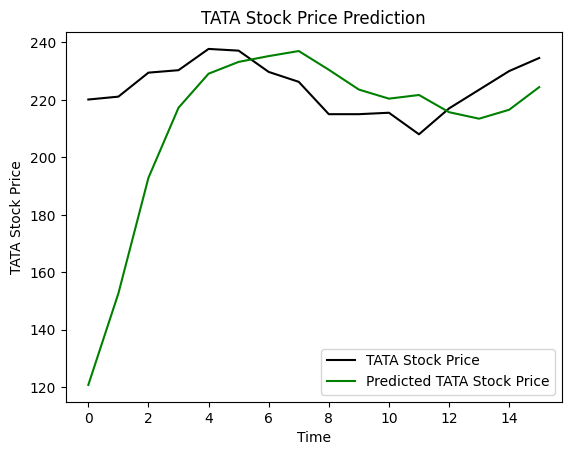

In [15]:
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/tatatest.csv'
dataset_test = pd.read_csv(url)
real_stock_price = dataset_test.iloc[:, 1:2].values
dataset_total = pd.concat((dataset_train['Open'], dataset_test['Open']), axis = 0)
inputs = dataset_total[len(dataset_total) - len(dataset_test) - 60:].values
inputs = inputs.reshape(-1,1)
inputs = sc.transform(inputs)
X_test = []
for i in range(60, 76):
    X_test.append(inputs[i-60:i, 0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
# Prediction
predicted_stock_price = model.predict(X_test)
predicted_stock_price = sc.inverse_transform(predicted_stock_price)
plt.plot(real_stock_price, color = 'black', label = 'TATA Stock Price')
plt.plot(predicted_stock_price, color = 'green', label = 'Predicted TATA Stock Price')
plt.title('TATA Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('TATA Stock Price')
plt.legend()
plt.show()
print()

In [1]:
print(predicted_stock_price)

NameError: name 'predicted_stock_price' is not defined

#  save the model

In [ ]:
#model.save('tata_model.h5')